# QSAR DILI — FeatureNet + GNN + Graph Transformers

**Design:**
- **Training pool** : proxy-DILI-12133 + NCV-888 (all clinical DILI labels combined)
- **Val**           : 20% stratified holdout of pool (clinical → tracks test distribution)
- **Proxy features**: 7 assay RFs → probabilities concatenated to ECFP4 (FeatureNet)
- **Test**          : held-out 223 trainin
- **Assays**        : proxy RF training + GIN pretraining (Stage 1 TL) only — not DILI labels


In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import copy

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, DataStructs
RDLogger.DisableLog('rdApp.*')

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    roc_auc_score, average_precision_score, matthews_corrcoef,
    f1_score, confusion_matrix, roc_curve, precision_recall_curve
)
from xgboost import XGBClassifier

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import (GCNConv, GATConv, GINConv, SAGEConv,
    GPSConv, GINEConv, global_mean_pool)
from torch_geometric.utils import to_dense_batch, degree as pyg_degree

SEED   = 42
BASE   = '/Users/yaminichitikela/Desktop/qsar casepase'
DEVICE = torch.device('cpu')
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f'Device: {DEVICE}  |  All imports OK')

Device: cpu  |  All imports OK


---
## Step 1 — Lock Test Set First (Géron Ch.2)

In [2]:
def canon(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi))
        return Chem.MolToSmiles(mol) if mol else None
    except:
        return None

df_test = pd.read_csv(f'{BASE}/liver/test_data_heldouttest_DILIst_223.csv',
                       usecols=['smiles_r', 'TOXICITY'])
df_test['csmi']  = df_test['smiles_r'].apply(canon)
df_test['label'] = df_test['TOXICITY'].astype(int)
df_test = df_test.dropna(subset=['csmi']).drop_duplicates('csmi').reset_index(drop=True)
TEST_SMIS = set(df_test['csmi'])

n_pos = int(df_test.label.sum())
print(f'Test set locked: {len(df_test)} compounds  DILI+={n_pos}  DILI-={len(df_test)-n_pos}')
print(f'Positive prevalence: {n_pos/len(df_test)*100:.1f}%')

Test set locked: 222 compounds  DILI+=155  DILI-=67
Positive prevalence: 69.8%


---
## Step 2 — Load Clinical DILI Datasets (proxy-12133 + NCV-888)

In [3]:
def load_dili_csv(path, smi_col='smiles_r', label_col='TOXICITY', tag=''):
    df = pd.read_csv(path, usecols=[smi_col, label_col], low_memory=False)
    df['csmi']   = df[smi_col].apply(canon)
    df['label']  = df[label_col].astype(int)
    df['source'] = tag
    df = df.dropna(subset=['csmi']).drop_duplicates('csmi').reset_index(drop=True)
    return df[['csmi','label','source']]

proxy = load_dili_csv(f'{BASE}/liver/proxy-DILI_dataset_12133.csv', tag='proxy12133')
ncv   = load_dili_csv(f'{BASE}/liver/test_data_ncv_DILIst_888.csv',  tag='ncv888')

for name, df in [('Proxy-12133', proxy), ('NCV-888', ncv)]:
    print(f'  {name}: {len(df):,}  DILI+={int(df.label.sum()):,}  DILI-={int((df.label==0).sum()):,}')

  Proxy-12133: 7,873  DILI+=2,883  DILI-=4,990
  NCV-888: 874  DILI+=553  DILI-=321


---
## Step 3 — Load 7 Mechanistic Assay Datasets

In [5]:
ASSAY_CONFIGS = [
    {'name':'Mito',      'path':f'{BASE}/mito/AID_720635_cleaned.xlsx',
     'ftype':'excel', 'smi_col':'PUBCHEM_EXT_DATASOURCE_SMILES',
     'out_col':'PUBCHEM_ACTIVITY_OUTCOME', 'score_col':'PUBCHEM_ACTIVITY_SCORE'},
    {'name':'Caspase',   'path':f'{BASE}/caspase/combined_hepg2_casepase.csv',
     'ftype':'csv',   'smi_col':'PUBCHEM_EXT_DATASOURCE_SMILES',
     'out_col':'PUBCHEM_ACTIVITY_OUTCOME', 'score_col':None},
    {'name':'BSEP',      'path':f'{BASE}/liver/AID_686978_datatable.csv',
     'ftype':'csv',   'smi_col':'PUBCHEM_EXT_DATASOURCE_SMILES',
     'out_col':'PUBCHEM_ACTIVITY_OUTCOME', 'score_col':None},
    {'name':'ARE743067', 'path':f'{BASE}/cleaned_datasets/AID_743067_datatable.csv',
     'ftype':'csv',   'smi_col':'PUBCHEM_EXT_DATASOURCE_SMILES',
     'out_col':'PUBCHEM_ACTIVITY_OUTCOME', 'score_col':None},
    {'name':'PPARg',     'path':f'{BASE}/cleaned_datasets/AID_743140_datatable.csv',
     'ftype':'csv',   'smi_col':'PUBCHEM_EXT_DATASOURCE_SMILES',
     'out_col':'PUBCHEM_ACTIVITY_OUTCOME', 'score_col':None},
    {'name':'ReactMet',  'path':f'{BASE}/liver/AID_743202_datatable.csv',
     'ftype':'csv',   'smi_col':'PUBCHEM_EXT_DATASOURCE_SMILES',
     'out_col':'PUBCHEM_ACTIVITY_OUTCOME', 'score_col':None},
    {'name':'ARE-bla',   'path':f'{BASE}/cleaned_datasets/AID_651741_datatable.csv',
     'ftype':'csv',   'smi_col':'PUBCHEM_EXT_DATASOURCE_SMILES',
     'out_col':'PUBCHEM_ACTIVITY_OUTCOME', 'score_col':None},
]

are_frames = []
for cfg in ASSAY_CONFIGS:
    raw = pd.read_excel(cfg['path']) if cfg['ftype']=='excel' else pd.read_csv(cfg['path'], low_memory=False)
    raw['csmi'] = raw[cfg['smi_col']].apply(canon)
    if cfg['score_col'] and cfg['score_col'] in raw.columns:
        raw['label'] = (raw[cfg['score_col']] >= 40).astype(int)
    else:
        raw['label'] = (raw[cfg['out_col']].str.upper() == 'ACTIVE').astype(int)
    df_a = (raw.dropna(subset=['csmi'])
               .drop_duplicates('csmi')
               .reset_index(drop=True))
    df_a = df_a[~df_a['csmi'].isin(TEST_SMIS)]  # no test leakage
    are_frames.append(df_a[['csmi','label']])
    print(f"  {cfg['name']:<12}: {len(df_a):>7,}  active={int(df_a.label.sum()):,} ({df_a.label.mean()*100:.1f}%)")

  Mito        :   8,031  active=1,399 (17.4%)
  Caspase     :   7,650  active=235 (3.1%)
  BSEP        : 416,743  active=62,630 (15.0%)
  ARE743067   :   8,031  active=306 (3.8%)
  PPARg       :   8,031  active=205 (2.6%)
  ReactMet    :   7,265  active=403 (5.5%)
  ARE-bla     :   2,264  active=493 (21.8%)


---
## Step 4 — Feature Engineering (ECFP4 + Graph)

In [6]:
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

ATOM_SYMBOLS = [6,7,8,16,9,15,17,35,53]   # C N O S F P Cl Br I
BOND_DIM = 6                                # 4 bond types + conjugated + in_ring

def one_hot(val, choices):
    v = [0]*len(choices)
    try: v[choices.index(val)] = 1
    except ValueError: pass
    return v

def atom_feat(atom):
    from rdkit.Chem import rdchem
    return (one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS)    # 9: element
          + [atom.GetDegree()/6.0]                        # 1: degree
          + [atom.GetFormalCharge()/4.0]                  # 1: charge
          + one_hot(int(atom.GetHybridization()),[2,3,4,5])  # 4: hybridisation
          + [int(atom.GetIsAromatic())]                   # 1: aromaticity
          + [int(atom.IsInRing())]                        # 1: ring
          + [atom.GetTotalNumHs()/4.0]                    # 1: H count
          + [atom.GetMass()/100.0])                       # 1: mass  → 18-dim total

def bond_feat(bond):
    from rdkit.Chem import BondType
    bt = bond.GetBondType()
    return ([int(bt==BondType.SINGLE), int(bt==BondType.DOUBLE),
             int(bt==BondType.TRIPLE), int(bt==BondType.AROMATIC)]
          + [int(bond.GetIsConjugated())]
          + [int(bond.IsInRing())])                       # 6-dim

def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None or mol.GetNumAtoms() == 0: return None
    x  = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_feat(bond)
        ei += [[i,j],[j,i]]; ea += [bf, bf]
    if not ei: return None
    return Data(x=x,
                edge_index=torch.tensor(ei, dtype=torch.long).t().contiguous(),
                edge_attr=torch.tensor(ea, dtype=torch.float),
                y=torch.tensor([label], dtype=torch.float))

ATOM_DIM = len(atom_feat(Chem.MolFromSmiles('C').GetAtomWithIdx(0)))
print(f'Atom dim={ATOM_DIM}  Bond dim={BOND_DIM}')

Atom dim=19  Bond dim=6


---
## Step 5 — Build Training Pool (proxy-12133 + NCV-888 combined)

In [7]:
def majority_label(labels):
    return 1 if labels.sum() >= len(labels)/2 else 0

proxy_t = proxy[['csmi','label']].copy(); proxy_t['source'] = 'proxy12133'
ncv_t   = ncv[['csmi','label']].copy();   ncv_t['source']   = 'ncv888'
all_raw = pd.concat([proxy_t, ncv_t], ignore_index=True)

n_leak  = all_raw['csmi'].isin(TEST_SMIS).sum()
all_raw = all_raw[~all_raw['csmi'].isin(TEST_SMIS)].reset_index(drop=True)

df_dili = (all_raw.groupby('csmi', sort=False)
           .agg(label=('label', majority_label),
                source=('source', lambda x: '|'.join(sorted(set(x)))))
           .reset_index())

assert len(set(df_dili['csmi']) & TEST_SMIS) == 0, 'Leakage!'
n_pos = int((df_dili.label==1).sum()); n_neg = int((df_dili.label==0).sum())
print(f'Pool: {len(df_dili):,}  DILI+={n_pos:,}  DILI-={n_neg:,}  (removed {n_leak} test overlaps)')
print(f'  Ratio neg:pos = {n_neg/n_pos:.1f}:1')

Pool: 8,747  DILI+=3,436  DILI-=5,311  (removed 0 test overlaps)
  Ratio neg:pos = 1.5:1


In [8]:
def build_features(df_src, tag=''):
    fps   = df_src['csmi'].apply(smiles_to_ecfp4)
    ok    = fps.notna().values
    df_v  = df_src[ok].reset_index(drop=True)
    X_fp  = np.vstack(fps[ok].values)
    y_lbl = df_v['label'].values
    graphs_raw = [mol_to_graph(smi, int(lbl))
                  for smi, lbl in zip(df_v['csmi'], y_lbl)]
    g_ok   = np.array([g is not None for g in graphs_raw])
    graphs = [g for g, ok2 in zip(graphs_raw, g_ok) if ok2]
    X_fp   = X_fp[g_ok]; y_lbl = y_lbl[g_ok]
    df_v   = df_v[g_ok].reset_index(drop=True)
    print(f'{tag}: {X_fp.shape}  DILI+={int(y_lbl.sum()):,}  DILI-={int((y_lbl==0).sum()):,}')
    return X_fp, y_lbl, graphs, df_v

print('Building training pool features ...')
X_all, y_all, graphs_dili, df_valid = build_features(df_dili, 'Pool(proxy+NCV)')

df_te_src = df_test[['csmi','label']].copy(); df_te_src['source'] = 'test'
print('Building test features ...')
X_te, y_te, graphs_te, df_te_valid = build_features(df_te_src, 'Test-223')
print(f'ECFP4 dim: {X_all.shape[1]}')

Building training pool features ...
Pool(proxy+NCV): (8746, 2048)  DILI+=3,435  DILI-=5,311
Building test features ...
Test-223: (222, 2048)  DILI+=155  DILI-=67
ECFP4 dim: 2048


---
## Step 6 — FeatureNet: Train One RF per Assay 

In [9]:
PROXY_ASSAYS = [
    ('p_mito',      are_frames[0]),
    ('p_caspase',   are_frames[1]),
    ('p_bsep',      are_frames[2]),
    ('p_are743067', are_frames[3]),
    ('p_ppar',      are_frames[4]),
    ('p_reactmet',  are_frames[5]),
    ('p_are_bla',   are_frames[6]),
]
N_PROXY = len(PROXY_ASSAYS)  # 7

print('=== FeatureNet: Training proxy RFs ===')
proxy_rfs = {}

for pname, df_assay in PROXY_ASSAYS:
    df_a  = df_assay[~df_assay['csmi'].isin(TEST_SMIS)].copy()
    fps_a = df_a['csmi'].apply(smiles_to_ecfp4)
    ok_a  = fps_a.notna().values
    X_a   = np.vstack(fps_a[ok_a].values)
    y_a   = df_a['label'].values[ok_a]
    rf    = RandomForestClassifier(n_estimators=200, max_features='sqrt',
                                    class_weight='balanced', n_jobs=-1, random_state=SEED)
    rf.fit(X_a, y_a)
    proxy_rfs[pname] = rf
    tr_auc = roc_auc_score(y_a, rf.predict_proba(X_a)[:,1])
    print(f'  {pname:<14}: {len(X_a):>7,} compounds  train_AUC={tr_auc:.4f}  pos={y_a.mean():.1%}')

# Predict proxy probs for training pool
proxy_tr = np.column_stack([proxy_rfs[p].predict_proba(X_all)[:,1]
                             for p,_ in PROXY_ASSAYS]).astype(np.float32)
# Predict proxy probs for test set
proxy_te = np.column_stack([proxy_rfs[p].predict_proba(X_te)[:,1]
                             for p,_ in PROXY_ASSAYS]).astype(np.float32)

# Augmented feature matrices: ECFP4 + 7 proxy probs
X_all_aug = np.hstack([X_all, proxy_tr]).astype(np.float32)
X_te_aug  = np.hstack([X_te,  proxy_te]).astype(np.float32)

# Attach proxy to graph objects (shape 1xN_PROXY per graph for DataLoader batching)
for i, g in enumerate(graphs_dili):
    g.proxy = torch.tensor(proxy_tr[i], dtype=torch.float).reshape(1, N_PROXY)
for i, g in enumerate(graphs_te):
    g.proxy = torch.tensor(proxy_te[i], dtype=torch.float).reshape(1, N_PROXY)

print(f'\nAugmented feature dim: {X_all_aug.shape[1]}  (ECFP4 {X_all.shape[1]} + {N_PROXY} proxy)')

=== FeatureNet: Training proxy RFs ===
  p_mito        :   8,031 compounds  train_AUC=0.9990  pos=17.4%
  p_caspase     :   7,650 compounds  train_AUC=0.9987  pos=3.1%
  p_bsep        : 416,743 compounds  train_AUC=0.9996  pos=15.0%
  p_are743067   :   8,031 compounds  train_AUC=0.9974  pos=3.8%
  p_ppar        :   8,031 compounds  train_AUC=0.9999  pos=2.6%
  p_reactmet    :   7,265 compounds  train_AUC=0.9987  pos=5.5%
  p_are_bla     :   2,264 compounds  train_AUC=0.9998  pos=21.8%

Augmented feature dim: 2055  (ECFP4 2048 + 7 proxy)


---
## Step 7 — Stratified 80/20 Train/Val Split

In [10]:
# Stratified 80/20 split of combined clinical pool
idx_all = np.arange(len(y_all))
idx_pool, idx_val = train_test_split(
    idx_all, test_size=0.20, stratify=y_all, random_state=SEED)

y_pool = y_all[idx_pool]

# 1:1 downsample majority class in training pool only
pos_pool = idx_pool[y_pool==1]
neg_pool = idx_pool[y_pool==0]
n_min    = min(len(pos_pool), len(neg_pool))
rng      = np.random.RandomState(SEED)
idx_tr   = np.concatenate([
    rng.choice(pos_pool, n_min, replace=False) if len(pos_pool)>n_min else pos_pool,
    rng.choice(neg_pool, n_min, replace=False) if len(neg_pool)>n_min else neg_pool
])
rng.shuffle(idx_tr)

y_tr  = y_all[idx_tr]
y_val = y_all[idx_val]

n_neg_tr = int((y_tr==0).sum()); n_pos_tr = int((y_tr==1).sum())
SW_TR = n_neg_tr / n_pos_tr   # for pos_weight (≈1.0 after 1:1 balance)

splits = {
    'X_train': X_all[idx_tr],    'y_train': y_tr,
    'X_val'  : X_all[idx_val],   'y_val'  : y_val,
    'X_test' : X_te,             'y_test' : y_te,
    'g_train': [graphs_dili[i] for i in idx_tr],
    'g_val'  : [graphs_dili[i] for i in idx_val],
    'g_test' : graphs_te,
}
splits_prx = {
    'X_train': X_all_aug[idx_tr],  'y_train': y_tr,
    'X_val'  : X_all_aug[idx_val], 'y_val'  : y_val,
    'X_test' : X_te_aug,           'y_test' : y_te,
}

print('Split summary:')
for k, lbl in [('train','Train 1:1 balanced'), ('val','Val 20% clinical'), ('test','Test held-out 223')]:
    yy = splits[f'y_{k}']
    print(f'  {lbl:<22}: {len(yy):>6,}  DILI+={int(yy.sum()):,}  DILI-={int((yy==0).sum()):,}')
print(f'  SW_TR={SW_TR:.3f} | ECFP4={X_all.shape[1]} | Augmented={X_all_aug.shape[1]}')

Split summary:
  Train 1:1 balanced    :  5,496  DILI+=2,748  DILI-=2,748
  Val 20% clinical      :  1,750  DILI+=687  DILI-=1,063
  Test held-out 223     :    222  DILI+=155  DILI-=67
  SW_TR=1.000 | ECFP4=2048 | Augmented=2055


---
## Step 8 — Evaluation Helper

In [11]:
METRIC_COLS = ['Model','Sensitivity','Specificity','CCR','ROC-AUC','PR-AUC','MCC','F1']

def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn)>0 else 0
    spec = tn/(tn+fp) if (tn+fp)>0 else 0
    return {
        'Model'      : name,
        'Sensitivity': round(sens*100, 1),
        'Specificity': round(spec*100, 1),
        'CCR'        : round((sens+spec)/2*100, 1),
        'ROC-AUC'    : round(roc_auc_score(y_true, y_prob), 4),
        'PR-AUC'     : round(average_precision_score(y_true, y_prob), 4),
        'MCC'        : round(matthews_corrcoef(y_true, y_pred), 4),
        'F1'         : round(f1_score(y_true, y_pred), 4),
        'TP':tp,'TN':tn,'FP':fp,'FN':fn
    }
print('evaluate() defined.')

evaluate() defined.


---
## Step 9 — Classical ML: RF + XGBoost (ECFP4 and +Proxy)

In [12]:
X_tr  = splits['X_train'];    y_tr  = splits['y_train']
X_val = splits['X_val'];      y_val = splits['y_val']

X_tr_p  = splits_prx['X_train']
X_val_p = splits_prx['X_val']

classical_results = {}
all_test_probs    = {}

# ── Random Forest (ECFP4) ────────────────────────────────────────────────────
rf_grid = ParameterGrid({'n_estimators':[200,400],
                          'max_features':['sqrt',0.3],
                          'min_samples_leaf':[1,3],
                          'max_depth':[None,20]})
print('RF (ECFP4) hyperparameter search ...')
best_val, best_rf = 0, None
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_tr, y_tr)
    v = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if v > best_val: best_val, best_rf = v, clf
prob_rf = best_rf.predict_proba(X_te)[:,1]
r = evaluate(y_te, prob_rf, 'Random Forest')
classical_results['RF'] = (best_rf, r); all_test_probs['Random Forest'] = prob_rf
print(f'  RF        val={best_val:.4f}  test ROC-AUC={r["ROC-AUC"]}  PR-AUC={r["PR-AUC"]}')

# ── RF + Proxy ────────────────────────────────────────────────────────────────
print('RF+Proxy hyperparameter search ...')
best_val, best_rfp = 0, None
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_tr_p, y_tr)
    v = roc_auc_score(y_val, clf.predict_proba(X_val_p)[:,1])
    if v > best_val: best_val, best_rfp = v, clf
prob_rfp = best_rfp.predict_proba(X_te_aug)[:,1]
r = evaluate(y_te, prob_rfp, 'RF+Proxy')
classical_results['RF+Proxy'] = (best_rfp, r); all_test_probs['RF+Proxy'] = prob_rfp
print(f'  RF+Proxy  val={best_val:.4f}  test ROC-AUC={r["ROC-AUC"]}  PR-AUC={r["PR-AUC"]}')

# ── XGBoost (ECFP4) ──────────────────────────────────────────────────────────
xgb_grid = ParameterGrid({'n_estimators':[200,400],
                           'max_depth':[4,6],
                           'learning_rate':[0.05,0.1],
                           'subsample':[0.8,1.0]})
print('XGBoost (ECFP4) hyperparameter search ...')
sw = (y_tr==0).sum()/(y_tr==1).sum()
best_val, best_xgb = 0, None
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=sw, use_label_encoder=False,
                         eval_metric='logloss', random_state=SEED, n_jobs=-1)
    clf.fit(X_tr, y_tr)
    v = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if v > best_val: best_val, best_xgb = v, clf
prob_xgb = best_xgb.predict_proba(X_te)[:,1]
r = evaluate(y_te, prob_xgb, 'XGBoost')
classical_results['XGB'] = (best_xgb, r); all_test_probs['XGBoost'] = prob_xgb
print(f'  XGBoost   val={best_val:.4f}  test ROC-AUC={r["ROC-AUC"]}  PR-AUC={r["PR-AUC"]}')

# ── XGB + Proxy ───────────────────────────────────────────────────────────────
print('XGB+Proxy hyperparameter search ...')
best_val, best_xgbp = 0, None
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=sw, use_label_encoder=False,
                         eval_metric='logloss', random_state=SEED, n_jobs=-1)
    clf.fit(X_tr_p, y_tr)
    v = roc_auc_score(y_val, clf.predict_proba(X_val_p)[:,1])
    if v > best_val: best_val, best_xgbp = v, clf
prob_xgbp = best_xgbp.predict_proba(X_te_aug)[:,1]
r = evaluate(y_te, prob_xgbp, 'XGB+Proxy')
classical_results['XGB+Proxy'] = (best_xgbp, r); all_test_probs['XGB+Proxy'] = prob_xgbp
print(f'  XGB+Proxy val={best_val:.4f}  test ROC-AUC={r["ROC-AUC"]}  PR-AUC={r["PR-AUC"]}')

# ── Ensemble: average RF+Proxy and XGB+Proxy ─────────────────────────────────
prob_ens = (prob_rfp + prob_xgbp) / 2
r = evaluate(y_te, prob_ens, 'Consensus (RF+XGB+Proxy)')
classical_results['Consensus'] = (None, r); all_test_probs['Consensus (RF+XGB+Proxy)'] = prob_ens
print(f'  Ensemble  test ROC-AUC={r["ROC-AUC"]}  PR-AUC={r["PR-AUC"]}')

RF (ECFP4) hyperparameter search ...
  RF        val=0.7271  test ROC-AUC=0.562  PR-AUC=0.7453
RF+Proxy hyperparameter search ...
  RF+Proxy  val=0.7504  test ROC-AUC=0.5568  PR-AUC=0.7291
XGBoost (ECFP4) hyperparameter search ...
  XGBoost   val=0.7074  test ROC-AUC=0.5547  PR-AUC=0.7544
XGB+Proxy hyperparameter search ...
  XGB+Proxy val=0.7476  test ROC-AUC=0.544  PR-AUC=0.7259
  Ensemble  test ROC-AUC=0.5539  PR-AUC=0.7272


---
## Step 10 — Applicability Domain (k-NN Jaccard)

In [13]:
nn_ad = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_ad.fit(splits['X_train'])
d_tr, _ = nn_ad.kneighbors(splits['X_train'])
thr = d_tr.mean(axis=1).mean() + 1.5 * d_tr.mean(axis=1).std()
d_te, _ = nn_ad.kneighbors(X_te)
in_ad   = d_te.mean(axis=1) <= thr
print(f'AD threshold (mean+1.5σ): {thr:.4f}')
print(f'Test coverage: {in_ad.mean()*100:.1f}%  ({in_ad.sum()}/{len(in_ad)} within AD)')

AD threshold (mean+1.5σ): 0.6066
Test coverage: 17.6%  (39/222 within AD)


---
## Step 11 — Direct GNN Models (GCN / GAT / GIN / SAGE)

In [14]:
class MolGNN(nn.Module):
    """Generic GNN with FeatureNet proxy injection after global mean pool."""
    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 conv_type='GCN', heads=4, proxy_dim=0):
        super().__init__()
        self.proxy_dim  = proxy_dim
        self.dropout    = dropout
        self.input_proj = nn.Linear(in_dim, hidden)
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            if conv_type == 'GCN':
                self.convs.append(GCNConv(hidden, hidden))
            elif conv_type == 'GAT':
                self.convs.append(GATConv(hidden, hidden//heads, heads=heads,
                                           dropout=dropout, edge_dim=BOND_DIM))
            elif conv_type == 'GIN':
                mlp = nn.Sequential(nn.Linear(hidden,hidden), nn.ReLU(),
                                     nn.BatchNorm1d(hidden), nn.Linear(hidden,hidden))
                self.convs.append(GINConv(mlp))
            elif conv_type == 'SAGE':
                self.convs.append(SAGEConv(hidden, hidden))
            self.bns.append(nn.BatchNorm1d(hidden))
        self.head = nn.Sequential(
            nn.Linear(hidden + proxy_dim, hidden//2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden//2, 1))

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        h = self.input_proj(x)
        for conv, bn in zip(self.convs, self.bns):
            if isinstance(conv, GATConv):
                h = bn(F.relu(conv(h, ei, edge_attr=ea)))
            else:
                h = bn(F.relu(conv(h, ei)))
            h = F.dropout(h, p=self.dropout, training=self.training)
        h_g = global_mean_pool(h, batch)
        if self.proxy_dim > 0 and hasattr(data, 'proxy'):
            proxy = data.proxy.view(h_g.size(0), self.proxy_dim)
            h_g   = torch.cat([h_g, proxy], dim=-1)
        return self.head(h_g).squeeze(-1)

def train_epoch(model, loader, opt, crit, device):
    model.train()
    for batch in loader:
        batch = batch.to(device)
        opt.zero_grad()
        crit(model(batch), batch.y.squeeze()).backward()
        opt.step()

def get_probs(model, loader, device):
    model.eval()
    probs, labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            probs.extend(torch.sigmoid(model(batch)).cpu().numpy())
            labels.extend(batch.y.squeeze().cpu().numpy())
    return np.array(probs), np.array(labels)

print('MolGNN, train_epoch, get_probs defined.')

MolGNN, train_epoch, get_probs defined.


In [15]:
GNN_CONFIGS = {
    'GCN' : {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':1e-3},
    'GAT' : {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':1e-3, 'heads':4},
    'GIN' : {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':1e-3},
    'SAGE': {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':1e-3},
}
EPOCHS   = 80
PATIENCE = 20
BATCH    = 64

pos_w = torch.tensor([SW_TR], dtype=torch.float).to(DEVICE)
crit  = nn.BCEWithLogitsLoss(pos_weight=pos_w)

tr_loader = DataLoader(splits['g_train'], batch_size=BATCH, shuffle=True)
va_loader = DataLoader(splits['g_val'],   batch_size=BATCH)
te_loader = DataLoader(splits['g_test'],  batch_size=BATCH)

gnn_results = {}; gnn_probs = {}

print('=== Direct GNN Training ===')
for arch, cfg in GNN_CONFIGS.items():
    lr  = cfg.pop('lr', 1e-3)
    model = MolGNN(ATOM_DIM, conv_type=arch, **cfg, proxy_dim=N_PROXY).to(DEVICE)
    cfg['lr'] = lr  # restore
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode='max', patience=10, factor=0.5, min_lr=1e-5)
    best_val, best_state, no_imp = 0.0, None, 0

    for ep in range(EPOCHS):
        train_epoch(model, tr_loader, opt, crit, DEVICE)
        p_va, y_va = get_probs(model, va_loader, DEVICE)
        if len(np.unique(y_va)) < 2: continue
        auc_va = roc_auc_score(y_va, p_va)
        sched.step(auc_va)
        if auc_va > best_val:
            best_val  = auc_va
            best_state = copy.deepcopy(model.state_dict())
            no_imp    = 0
        else:
            no_imp += 1
        if no_imp >= PATIENCE:
            print(f'    {arch} early stop ep={ep+1}  best_val={best_val:.4f}')
            break

    model.load_state_dict(best_state)
    p_te, _ = get_probs(model, te_loader, DEVICE)
    r = evaluate(y_te, p_te, arch)
    gnn_results[arch] = r; gnn_probs[arch] = p_te
    print(f'  {arch:<6}  val={best_val:.4f}  test ROC-AUC={r["ROC-AUC"]}  PR-AUC={r["PR-AUC"]}')

# GNN consensus (average of all 4)
prob_gnn_ens = np.mean(list(gnn_probs.values()), axis=0)
r = evaluate(y_te, prob_gnn_ens, 'GNN-Consensus')
gnn_results['GNN-Consensus'] = r; gnn_probs['GNN-Consensus'] = prob_gnn_ens
print(f'  GNN-Consensus  test ROC-AUC={r["ROC-AUC"]}  PR-AUC={r["PR-AUC"]}')

=== Direct GNN Training ===
    GCN early stop ep=72  best_val=0.7389
  GCN     val=0.7389  test ROC-AUC=0.5508  PR-AUC=0.7444
  GAT     val=0.7329  test ROC-AUC=0.5364  PR-AUC=0.7298
    GIN early stop ep=69  best_val=0.7445
  GIN     val=0.7445  test ROC-AUC=0.5364  PR-AUC=0.7161
    SAGE early stop ep=76  best_val=0.7425
  SAGE    val=0.7425  test ROC-AUC=0.525  PR-AUC=0.7095
  GNN-Consensus  test ROC-AUC=0.538  PR-AUC=0.7288


---
## Step 12 — Transfer Learning: Pretrain GIN on Assays → Fine-tune on DILI

In [16]:
class GNNEncoder(nn.Module):
    """GIN encoder pretrained on assay data, fine-tuned on DILI."""
    def __init__(self, in_dim, hidden=256, n_layers=4, dropout=0.3):
        super().__init__()
        self.hidden = hidden; self.dropout = dropout
        self.input_proj = nn.Linear(in_dim, hidden)
        self.convs = nn.ModuleList(); self.bns = nn.ModuleList()
        for _ in range(n_layers):
            mlp = nn.Sequential(nn.Linear(hidden,hidden), nn.ReLU(), nn.Linear(hidden,hidden))
            self.convs.append(GINConv(mlp)); self.bns.append(nn.BatchNorm1d(hidden))

    def forward(self, data):
        h = self.input_proj(data.x)
        for conv, bn in zip(self.convs, self.bns):
            h = bn(F.relu(conv(h, data.edge_index)))
            h = F.dropout(h, p=self.dropout, training=self.training)
        return global_mean_pool(h, data.batch)

class ClassHead(nn.Module):
    """MLP head; proxy_dim=0 for assay pretraining, N_PROXY for DILI fine-tuning."""
    def __init__(self, hidden=256, dropout=0.3, proxy_dim=0):
        super().__init__()
        self.proxy_dim = proxy_dim
        self.net = nn.Sequential(
            nn.Linear(hidden+proxy_dim, hidden//2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden//2, 1))

    def forward(self, h, proxy=None):
        if self.proxy_dim > 0 and proxy is not None:
            h = torch.cat([h, proxy], dim=-1)
        return self.net(h).squeeze(-1)

# ── Stage 1: Pretrain on all 7 assay datasets ────────────────────────────────
print('Building assay graphs ...')
assay_df     = pd.concat(are_frames, ignore_index=True)
assay_graphs = [mol_to_graph(s,int(l)) for s,l in zip(assay_df['csmi'],assay_df['label'])]
ok_a         = [g is not None for g in assay_graphs]
assay_graphs = [g for g,ok2 in zip(assay_graphs,ok_a) if ok2]
y_assay      = assay_df['label'].values[ok_a]
print(f'Assay graphs: {len(assay_graphs):,}')

idx_ap = np.arange(len(assay_graphs))
idx_ap_tr, idx_ap_va = train_test_split(idx_ap, test_size=0.10,
                                         stratify=y_assay, random_state=SEED)
a_tr_ld = DataLoader([assay_graphs[i] for i in idx_ap_tr], batch_size=256, shuffle=True)
a_va_ld = DataLoader([assay_graphs[i] for i in idx_ap_va], batch_size=256)

HIDDEN = 256; N_LAYERS = 4
encoder    = GNNEncoder(ATOM_DIM, hidden=HIDDEN, n_layers=N_LAYERS).to(DEVICE)
assay_head = ClassHead(hidden=HIDDEN).to(DEVICE)

pw_a = torch.tensor([(y_assay[idx_ap_tr]==0).sum()/max((y_assay[idx_ap_tr]==1).sum(),1)],
                     dtype=torch.float).to(DEVICE)
crit_pre  = nn.BCEWithLogitsLoss(pos_weight=pw_a)
opt_pre   = torch.optim.Adam(list(encoder.parameters())+list(assay_head.parameters()), lr=1e-3)
sched_pre = torch.optim.lr_scheduler.ReduceLROnPlateau(opt_pre, mode='max', patience=5, factor=0.5)

best_pre_auc, best_enc_state = 0.0, None
print('=== Stage 1: Pretraining ===')
for ep in range(30):
    encoder.train(); assay_head.train()
    for batch in a_tr_ld:
        batch = batch.to(DEVICE); opt_pre.zero_grad()
        crit_pre(assay_head(encoder(batch)), batch.y.squeeze()).backward(); opt_pre.step()

    encoder.eval(); assay_head.eval()
    pp, pl = [], []
    with torch.no_grad():
        for batch in a_va_ld:
            batch = batch.to(DEVICE)
            pp.extend(torch.sigmoid(assay_head(encoder(batch))).cpu().numpy())
            pl.extend(batch.y.squeeze().cpu().numpy())
    auc_pre = roc_auc_score(pl, pp) if len(np.unique(pl))>1 else 0.5
    sched_pre.step(auc_pre)
    if auc_pre > best_pre_auc:
        best_pre_auc = auc_pre
        best_enc_state = copy.deepcopy(encoder.state_dict())
    if (ep+1) % 5 == 0:
        print(f'  ep={ep+1:>2}  assay_val_AUC={auc_pre:.4f}  best={best_pre_auc:.4f}')
encoder.load_state_dict(best_enc_state)
print(f'Pretraining done. Best assay AUC={best_pre_auc:.4f}')

Building assay graphs ...
Assay graphs: 457,903
=== Stage 1: Pretraining ===
  ep= 5  assay_val_AUC=0.7556  best=0.7556
  ep=10  assay_val_AUC=0.7790  best=0.7816
  ep=15  assay_val_AUC=0.7839  best=0.7902
  ep=20  assay_val_AUC=0.8007  best=0.8025
  ep=25  assay_val_AUC=0.8070  best=0.8110
  ep=30  assay_val_AUC=0.8154  best=0.8154
Pretraining done. Best assay AUC=0.8154


In [17]:
# ── Stage 2: Fine-tune with gradual unfreezing 
dili_head = ClassHead(hidden=HIDDEN, proxy_dim=N_PROXY).to(DEVICE)

pw_d = torch.tensor([(y_tr==0).sum()/max((y_tr==1).sum(),1)], dtype=torch.float).to(DEVICE)
crit_ft = nn.BCEWithLogitsLoss(pos_weight=pw_d)

clin_tr_ld = DataLoader(splits['g_train'], batch_size=64, shuffle=True)
clin_va_ld = DataLoader(splits['g_val'],   batch_size=64)
clin_te_ld = DataLoader(splits['g_test'],  batch_size=64)

g_best_auc, g_best_enc, g_best_head = 0.0, None, None

def ft_phase(name, params, n_ep, lr, patience=8):
    global g_best_auc, g_best_enc, g_best_head
    opt   = torch.optim.Adam(params, lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', patience=4, factor=0.5)
    no_imp = 0
    for ep in range(n_ep):
        encoder.train(); dili_head.train()
        for batch in clin_tr_ld:
            batch = batch.to(DEVICE); opt.zero_grad()
            h     = encoder(batch)
            proxy = batch.proxy.view(h.size(0), N_PROXY)
            crit_ft(dili_head(h, proxy), batch.y.squeeze()).backward(); opt.step()
        encoder.eval(); dili_head.eval()
        pv, yv = [], []
        with torch.no_grad():
            for batch in clin_va_ld:
                batch = batch.to(DEVICE)
                h     = encoder(batch)
                proxy = batch.proxy.view(h.size(0), N_PROXY)
                pv.extend(torch.sigmoid(dili_head(h, proxy)).cpu().numpy())
                yv.extend(batch.y.squeeze().cpu().numpy())
        auc_v = roc_auc_score(yv, pv) if len(np.unique(yv))>1 else 0.5
        sched.step(auc_v)
        if auc_v > g_best_auc:
            g_best_auc  = auc_v
            g_best_enc  = copy.deepcopy(encoder.state_dict())
            g_best_head = copy.deepcopy(dili_head.state_dict())
            no_imp = 0
        else:
            no_imp += 1
        if no_imp >= patience:
            break
    print(f'  {name}: stopped ep={ep+1}  best_val={g_best_auc:.4f}')

# Freeze encoder completely for phase A
for p in encoder.parameters(): p.requires_grad_(False)

print('=== Stage 2: Fine-tuning ===')
ft_phase('A: head only',    list(dili_head.parameters()), 20, 1e-3)
for p in encoder.convs[3].parameters(): p.requires_grad_(True)
for p in encoder.bns[3].parameters():   p.requires_grad_(True)
ft_phase('B1: +layer3',    list(dili_head.parameters())+
         list(encoder.convs[3].parameters())+list(encoder.bns[3].parameters()), 15, 3e-4)
for p in encoder.convs[2].parameters(): p.requires_grad_(True)
for p in encoder.bns[2].parameters():   p.requires_grad_(True)
ft_phase('B2: +layer2',    list(dili_head.parameters())+
         [p for p in encoder.parameters() if p.requires_grad], 15, 1e-4)
for p in encoder.parameters(): p.requires_grad_(True)
ft_phase('B3: all layers', list(encoder.parameters())+list(dili_head.parameters()), 20, 3e-5)

encoder.load_state_dict(g_best_enc); dili_head.load_state_dict(g_best_head)
encoder.eval(); dili_head.eval()
pt, yt = [], []
with torch.no_grad():
    for batch in clin_te_ld:
        batch = batch.to(DEVICE)
        h = encoder(batch); proxy = batch.proxy.view(h.size(0), N_PROXY)
        pt.extend(torch.sigmoid(dili_head(h, proxy)).cpu().numpy())
        yt.extend(batch.y.squeeze().cpu().numpy())

r_tl = evaluate(y_te, np.array(pt), 'TL-GIN')
gnn_results['TL-GIN'] = r_tl; gnn_probs['TL-GIN'] = np.array(pt)
print(f'TL-GIN  val={g_best_auc:.4f}  test ROC-AUC={r_tl["ROC-AUC"]}  PR-AUC={r_tl["PR-AUC"]}')

=== Stage 2: Fine-tuning ===
  A: head only: stopped ep=20  best_val=0.7267
  B1: +layer3: stopped ep=15  best_val=0.7292
  B2: +layer2: stopped ep=15  best_val=0.7318
  B3: all layers: stopped ep=19  best_val=0.7333
TL-GIN  val=0.7333  test ROC-AUC=0.5662  PR-AUC=0.7417


---
## Step 13 — Graph Transformers: GraphGPS + Graphormer-lite

In [18]:
class GraphGPS(nn.Module):
    """GraphGPS (Rampasek 2022): local GINe MPNN + global multi-head attention per layer.
    BatchNorm after each layer. Proxy features injected after global mean pool."""
    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3, heads=4, proxy_dim=0):
        super().__init__()
        self.proxy_dim  = proxy_dim
        self.input_proj = nn.Linear(in_dim, hidden)
        self.convs = nn.ModuleList([
            GPSConv(channels=hidden,
                    conv=GINEConv(nn.Sequential(
                        nn.Linear(hidden,hidden), nn.ReLU(),
                        nn.BatchNorm1d(hidden), nn.Linear(hidden,hidden)),
                        edge_dim=BOND_DIM),
                    heads=heads, dropout=dropout, attn_type='multihead')
            for _ in range(n_layers)])
        self.bns  = nn.ModuleList([nn.BatchNorm1d(hidden) for _ in range(n_layers)])
        self.drop = dropout
        self.head = nn.Sequential(nn.Linear(hidden+proxy_dim, hidden//2), nn.ReLU(),
                                   nn.Dropout(dropout), nn.Linear(hidden//2, 1))

    def forward(self, data):
        h = self.input_proj(data.x)
        for conv, bn in zip(self.convs, self.bns):
            h = bn(F.relu(conv(h, data.edge_index, data.batch, edge_attr=data.edge_attr)))
            h = F.dropout(h, p=self.drop, training=self.training)
        h_g = global_mean_pool(h, data.batch)
        if self.proxy_dim > 0 and hasattr(data, 'proxy'):
            h_g = torch.cat([h_g, data.proxy.view(h_g.size(0), self.proxy_dim)], dim=-1)
        return self.head(h_g).squeeze(-1)


class GraphormerLite(nn.Module):
    """Graphormer-lite (Ying 2021): degree centrality encoding + pre-LN Transformer.
    Proxy features injected after global mean pool."""
    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 heads=4, max_degree=10, proxy_dim=0):
        super().__init__()
        self.proxy_dim      = proxy_dim
        self.max_degree     = max_degree
        self.input_proj     = nn.Linear(in_dim, hidden)
        self.degree_encoder = nn.Embedding(max_degree+1, hidden)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=hidden, nhead=heads, dim_feedforward=hidden*4,
            dropout=dropout, batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.head = nn.Sequential(nn.Linear(hidden+proxy_dim, hidden//2), nn.ReLU(),
                                   nn.Dropout(dropout), nn.Linear(hidden//2, 1))

    def forward(self, data):
        x, ei, batch = data.x, data.edge_index, data.batch
        deg = pyg_degree(ei[0], x.size(0), dtype=torch.long).clamp(max=self.max_degree)
        h   = self.input_proj(x) + self.degree_encoder(deg)
        h_dense, mask = to_dense_batch(h, batch)
        h_out  = self.transformer(h_dense, src_key_padding_mask=~mask)
        h_g    = global_mean_pool(h_out[mask], batch)
        if self.proxy_dim > 0 and hasattr(data, 'proxy'):
            h_g = torch.cat([h_g, data.proxy.view(h_g.size(0), self.proxy_dim)], dim=-1)
        return self.head(h_g).squeeze(-1)

print('GraphGPS and GraphormerLite defined.')

GraphGPS and GraphormerLite defined.


In [19]:
GT_CONFIGS = {
    'GraphGPS'  : {'hidden':128, 'n_layers':3, 'dropout':0.3, 'heads':4, 'lr':1e-3},
    'Graphormer': {'hidden':128, 'n_layers':3, 'dropout':0.3, 'heads':4, 'lr':1e-3},
}

print('=== Graph Transformer Training ===')
print(f'  Epochs={EPOCHS}  Patience={PATIENCE}  Batch={BATCH}  Proxy={N_PROXY}')
for arch, cfg in GT_CONFIGS.items():
    lr = cfg['lr']
    kw = {k:v for k,v in cfg.items() if k != 'lr'}
    model = (GraphGPS(ATOM_DIM, **kw, proxy_dim=N_PROXY)
             if arch=='GraphGPS'
             else GraphormerLite(ATOM_DIM, **kw, proxy_dim=N_PROXY)).to(DEVICE)

    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode='max', patience=8, factor=0.5, min_lr=1e-5)
    best_val, best_state, no_imp = 0.0, None, 0

    for ep in range(EPOCHS):
        train_epoch(model, tr_loader, opt, crit, DEVICE)
        p_va, y_va = get_probs(model, va_loader, DEVICE)
        if len(np.unique(y_va)) < 2: continue
        auc_va = roc_auc_score(y_va, p_va)
        sched.step(auc_va)
        if auc_va > best_val:
            best_val = auc_va; best_state = copy.deepcopy(model.state_dict()); no_imp = 0
        else:
            no_imp += 1
        if no_imp >= PATIENCE:
            print(f'    {arch} early stop ep={ep+1}  best_val={best_val:.4f}'); break

    model.load_state_dict(best_state)
    p_te, _ = get_probs(model, te_loader, DEVICE)
    r = evaluate(y_te, p_te, arch)
    gnn_results[arch] = r; gnn_probs[arch] = p_te
    print(f'  {arch:<12}  val={best_val:.4f}  test ROC-AUC={r["ROC-AUC"]}  PR-AUC={r["PR-AUC"]}')

=== Graph Transformer Training ===
  Epochs=80  Patience=20  Batch=64  Proxy=7
    GraphGPS early stop ep=38  best_val=0.7212
  GraphGPS      val=0.7212  test ROC-AUC=0.5229  PR-AUC=0.7291
    Graphormer early stop ep=64  best_val=0.7241
  Graphormer    val=0.7241  test ROC-AUC=0.5277  PR-AUC=0.7195


---
## Step 14 — Final Results: All Models on Held-out 223

=== Final Results — All Models on Held-out 223 ===
                   Model  Sensitivity  Specificity  CCR  ROC-AUC  PR-AUC     MCC     F1
                  TL-GIN         65.8         47.8 56.8   0.5662  0.7417  0.1281 0.6986
           Random Forest         61.9         40.3 51.1   0.5620  0.7453  0.0211 0.6598
                RF+Proxy         65.8         41.8 53.8   0.5568  0.7291  0.0724 0.6892
                 XGBoost         62.6         38.8 50.7   0.5547  0.7544  0.0131 0.6621
Consensus (RF+XGB+Proxy)         65.8         34.3 50.1   0.5539  0.7272  0.0013 0.6777
                     GCN         61.9         40.3 51.1   0.5508  0.7444  0.0211 0.6598
               XGB+Proxy         63.9         35.8 49.8   0.5440  0.7259 -0.0029 0.6667
           GNN-Consensus         59.4         44.8 52.1   0.5380  0.7288  0.0384 0.6479
                     GAT         57.4         44.8 51.1   0.5364  0.7298  0.0203 0.6335
                     GIN         61.9         41.8 51.9   0.5364  0.7

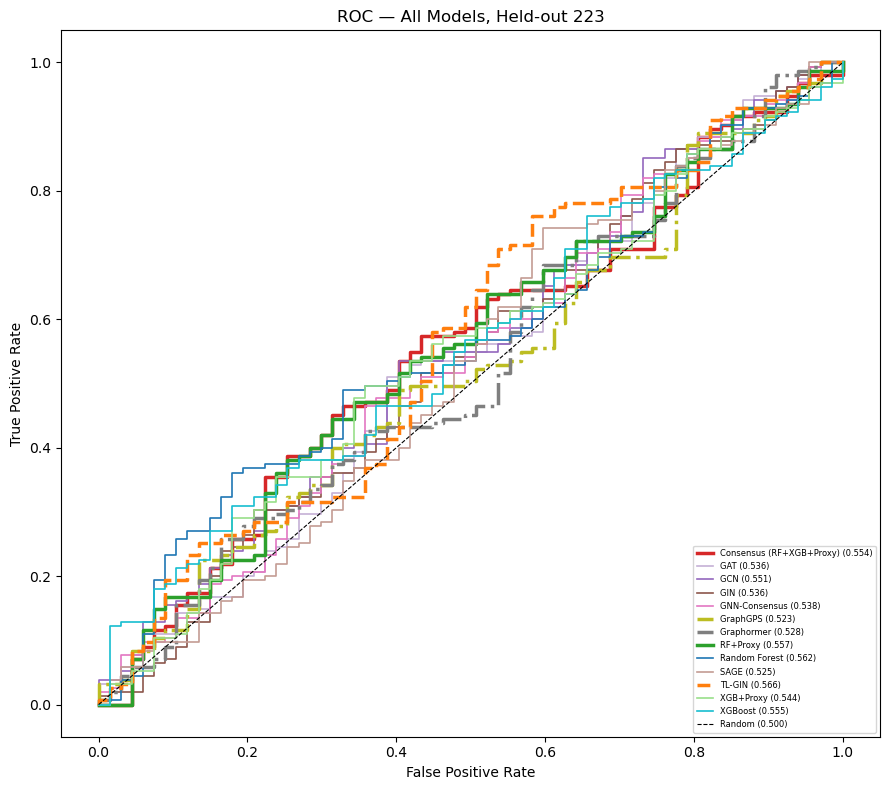

Done. Results saved.


In [20]:
GT_NAMES = {'GraphGPS','Graphormer'}
COLORS = {
    'Random Forest'          : '#1f77b4',
    'XGBoost'                : '#17becf',
    'RF+Proxy'               : '#2ca02c',
    'XGB+Proxy'              : '#98df8a',
    'Consensus (RF+XGB+Proxy)': '#d62728',
    'GCN':'#9467bd','GAT':'#c5b0d5','GIN':'#8c564b','SAGE':'#c49c94',
    'GNN-Consensus'          : '#e377c2',
    'TL-GIN'                 : '#ff7f0e',
    'GraphGPS'               : '#bcbd22',
    'Graphormer'             : '#7f7f7f',
}

all_rows = [r for _,r in classical_results.values()] + list(gnn_results.values())
final_df = (pd.DataFrame(all_rows)[METRIC_COLS]
            .sort_values('ROC-AUC', ascending=False)
            .reset_index(drop=True))
print('=== Final Results — All Models on Held-out 223 ===')
print(final_df.to_string(index=False))
final_df.to_csv(f'{BASE}/combined/qsar_v2_results.csv', index=False)

# ── 4-panel bar chart ─────────────────────────────────────────────────────────
def bar_color(name):
    if name == 'TL-GIN': return '#ff7f0e'
    if name in GT_NAMES: return '#bcbd22'
    if '+Proxy' in name or 'Consensus' in name: return '#2ca02c'
    if name in gnn_results: return '#9467bd'
    return '#1f77b4'

model_names = final_df['Model'].tolist()
colors_bar  = [bar_color(m) for m in model_names]
pos_prev    = y_te.mean()

fig, axes = plt.subplots(1, 4, figsize=(26, 6))
for ax, metric in zip(axes, ['ROC-AUC','PR-AUC','CCR','MCC']):
    vals = final_df[metric].values
    ax.bar(model_names, vals, color=colors_bar, edgecolor='white', lw=0.5)
    ax.set_title(metric, fontsize=13, fontweight='bold')
    ax.set_ylim(0, 1.0)
    ax.set_xticklabels(model_names, rotation=45, ha='right', fontsize=8)
    ax.axhline(0.5, color='gray', lw=0.8, ls='--')
    if metric == 'PR-AUC':
        ax.axhline(pos_prev, color='orange', lw=0.8, ls=':', label=f'random ({pos_prev:.2f})')
        ax.legend(fontsize=7)
    for bar, v in zip(ax.patches, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                f'{v:.3f}', ha='center', va='bottom', fontsize=6)

axes[0].legend(handles=[
    Patch(facecolor='#1f77b4', label='Classical (ECFP4)'),
    Patch(facecolor='#2ca02c', label='Classical+Proxy / Ensemble'),
    Patch(facecolor='#9467bd', label='Direct GNN'),
    Patch(facecolor='#ff7f0e', label='TL-GIN'),
    Patch(facecolor='#bcbd22', label='Graph Transformer'),
], fontsize=7, loc='lower right')
plt.suptitle('QSAR DILI — All Models | Test: Held-out 223 | Training: proxy-12133+NCV-888',
             fontsize=11)
plt.tight_layout()
plt.savefig(f'{BASE}/combined/qsar_v2_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# ── ROC curves ────────────────────────────────────────────────────────────────
all_probs_full = {**all_test_probs, **gnn_probs}
fig, ax = plt.subplots(figsize=(9,8))
for mname, prob in sorted(all_probs_full.items()):
    fpr, tpr, _ = roc_curve(y_te, prob)
    auc_val = roc_auc_score(y_te, prob)
    lw = 2.5 if mname in ('TL-GIN','RF+Proxy','Consensus (RF+XGB+Proxy)','GraphGPS','Graphormer') else 1.2
    ls = '--' if mname=='TL-GIN' else ('-.' if mname in GT_NAMES else '-')
    ax.plot(fpr, tpr, label=f'{mname} ({auc_val:.3f})',
            color=COLORS.get(mname,'gray'), lw=lw, ls=ls)
ax.plot([0,1],[0,1],'k--', lw=0.8, label='Random (0.500)')
ax.set(title='ROC — All Models, Held-out 223',
       xlabel='False Positive Rate', ylabel='True Positive Rate')
ax.legend(fontsize=6, loc='lower right')
plt.tight_layout()
plt.savefig(f'{BASE}/combined/qsar_v2_roc.png', dpi=150, bbox_inches='tight')
plt.show()
print('Done. Results saved.')

In [22]:
g = graphs_dili[0]
print('proxy tensor:', g.proxy)
print('shape:', g.proxy.shape)
print('values:', g.proxy.numpy())


proxy tensor: tensor([[0.0350, 0.0300, 0.0400, 0.0000, 0.0100, 0.0100, 0.1450]])
shape: torch.Size([1, 7])
values: [[0.035 0.03  0.04  0.    0.01  0.01  0.145]]
